# Notebook 1 — Artificial Neural Networks: Fundamentals

**Course:** From Introduction to Advanced Deep Learning · **Topic 1: ANN** · 4 hours
**Professor:** Dr. Muhammad Sajad · **Instructor/TA:** Ahsan Umar

> **Learning outcomes of this notebook.** By the end you will be able to (1) explain what an artificial
> neural network is and why it can approximate non-linear functions, (2) build one in PyTorch **incrementally**
> starting from a single neuron and ending at a dense fully-connected MLP, (3) read every component of a
> training loop — the forward pass, the loss, the backprop, the optimiser step — and (4) diagnose a sick
> training curve (underfit / overfit / dying ReLU). Every concept is introduced in a small code cell first,
> then explained in the surrounding markdown, so you can run and modify each cell before moving on.

---

## 1. What is an Artificial Neural Network?

An **artificial neural network (ANN)** is a function approximator built by composing many simple
**artificial neurons** into layers. Each neuron does almost nothing on its own — it computes a weighted
sum of its inputs and pushes the result through a non-linear **activation function**. The miracle is that
when you stack enough of these trivial units together and let a learning algorithm tune their weights,
the whole stack can approximate extremely complex mappings, from recognising handwritten digits to
translating English into German.

The name is deliberately biological. The artificial neuron is a *very* loose caricature of a biological
pyramidal cell: inputs play the role of dendrites, the weighted sum models what happens at the soma, the
activation function approximates the firing threshold, and the output stands in for the axon. Real neurons
fire spikes in time and are vastly more complicated; do not take the analogy too far. What we *do* keep
from biology is the **two big ideas** that make neural networks work:

1. **Depth** — stacking layers so that each layer re-represents its input in a more useful way for the
   next layer. Depth is what lets a small network solve XOR, recognise edges then shapes then objects,
   and generally build hierarchies of features.
2. **Non-linearity** — without a non-linear activation, any number of stacked linear layers collapse to
   a single linear layer (proof in §4), so the network can only learn linear boundaries, which are
   provably insufficient for almost any real-world task.

This notebook is structured so each of these ideas is introduced in its own runnable cell. We start with
a single linear neuron in §2, watch it fail on a non-linear problem, add more neurons in §3, add a
non-linear activation in §4, then widen and deepen in §5–§7 until we have a fully-connected MLP.

### The artificial neuron — a picture

Below is the canonical diagram of an artificial neuron. Inputs $x_1, \dots, x_n$ are multiplied by
weights $w_1, \dots, w_n$, summed, a bias $b$ is added, and the result $z = \sum_i w_i x_i + b$ is
passed through an activation function $\sigma$ to produce the output $a = \sigma(z)$.

![Artificial neuron](https://upload.wikimedia.org/wikipedia/commons/thumb/4/46/Colored_neural_network.svg/640px-Colored_neural_network.svg.png)

*Image: a feed-forward neural network, by Glosser.ca — Wikipedia CC BY-SA 3.0.*

## 2. The Artificial Neuron — A Single Linear Unit

### Purpose of this cell
Build the simplest possible neural-network component: **one neuron with one input**. The goal is to see
the math come alive in code before we add any complexity.

### Theory and mathematics
A single neuron computes a weighted sum of its inputs, adds a bias, and (for now) leaves the result
linear:

$$z = w \cdot x + b, \qquad a = \sigma(z)$$

For this first cell we use $\sigma(z) = z$ (the identity — i.e. **no activation yet**), so the neuron
is literally $a = w x + b$. Notice the parameter count: 1 weight + 1 bias = **2 parameters** for the
whole "model". Not very impressive, but it is the atom out of which everything else is built.

### What is the loss function here?
We are not training yet. The cell below just shows the forward pass on a toy input so you can see the
mechanics: instantiate the layer, feed it a number, read the output. Training (with MSE loss and
backprop) comes in §8–§9.

In [1]:
import torch
import torch.nn as nn

torch.manual_seed(0)  # reproducibility — see §12 for why this matters

# A single linear neuron: 1 input -> 1 output.
neuron = nn.Linear(in_features=1, out_features=1, bias=True)

print("Weights w (shape [1, 1]):", neuron.weight.data)
print("Bias    b (shape [1]):   ", neuron.bias.data)

# Feed a single input x = 2.0
x = torch.tensor([[2.0]])
a = neuron(x)
print()
print(f"Forward pass:  z = w*x + b = {neuron.weight.item():.4f} * {x.item():.1f} + {neuron.bias.item():.4f}")
print(f"               a = {a.item():.4f}")

# Parameter count
n_params = sum(p.numel() for p in neuron.parameters())
print(f"\nTotal parameters: {n_params}  (1 weight + 1 bias)")

Weights w (shape [1, 1]): tensor([[-0.0075]])
Bias    b (shape [1]):    tensor([0.5364])

Forward pass:  z = w*x + b = -0.0075 * 2.0 + 0.5364
               a = 0.5215

Total parameters: 2  (1 weight + 1 bias)


## 3. One Linear Layer — 10 Neurons, No Activation

### Purpose of this cell
Take the single neuron from §2 and replicate it 10 times in parallel. This is what `nn.Linear(1, 10)`
does: it produces a layer of 10 neurons, each with its own weight and bias, all reading the same input.

### Theory — the matrix form
Stacking 10 neurons means stacking 10 weight scalars into a weight **matrix** $W \in \mathbb{R}^{10 \times 1}$
and 10 biases into a vector $b \in \mathbb{R}^{10}$. The forward pass becomes a single matrix-vector product:

$$\mathbf{z} = W\mathbf{x} + \mathbf{b}, \qquad \mathbf{a} = \sigma(\mathbf{z})$$

With $\sigma$ = identity, this is just an affine map. With one input and 10 outputs, the layer has
$10 \times 1 + 10 = 20$ parameters. The shape of $\mathbf{a}$ is `[batch, 10]` — each row is the
10-dimensional output for one input.

### Why this is still not enough
Even with 10 (or 10 million) parallel linear neurons, **the layer is still a linear function**. A
linear combination of linear functions is linear. So if the relationship between input and target is
non-linear (like XOR, or like pixel-intensity → digit-class), no amount of width alone will help. We
fix that in §4 by adding an activation function.

### Loss function
Still no training in this cell — we just inspect the forward pass. Parameter count is now 20.

In [2]:
# A single linear layer: 1 input -> 10 outputs (10 neurons in parallel)
layer = nn.Linear(in_features=1, out_features=10, bias=True)

print(f"Weight shape: {layer.weight.shape}  (10 neurons, each with 1 weight)")
print(f"Bias   shape: {layer.bias.shape}  (one bias per neuron)")
print(f"Total parameters: {sum(p.numel() for p in layer.parameters())}")

# Feed it 3 inputs at once (batch dimension = 3)
x = torch.tensor([[1.0], [2.0], [3.0]])
print(f"\nInput batch shape: {x.shape}  (3 samples, 1 feature each)")

a = layer(x)
print(f"Output shape: {a.shape}  (3 samples, 10 neuron outputs each)")
print(f"\nOutput for the 3 inputs (rows) across 10 neurons (cols):")
print(a.detach().numpy().round(3))

Weight shape: torch.Size([10, 1])  (10 neurons, each with 1 weight)
Bias   shape: torch.Size([10])  (one bias per neuron)
Total parameters: 20

Input batch shape: torch.Size([3, 1])  (3 samples, 1 feature each)
Output shape: torch.Size([3, 10])  (3 samples, 10 neuron outputs each)

Output for the 3 inputs (rows) across 10 neurons (cols):
[[-1.778 -1.398 -0.797  0.305  0.376  1.393 -0.767 -0.171  0.061  0.634]
 [-2.601 -2.134 -1.183  0.573  0.356  2.186 -0.855  0.094 -0.241  0.437]
 [-3.424 -2.87  -1.568  0.842  0.336  2.979 -0.944  0.358 -0.543  0.241]]


## 4. Adding Non-Linearity — Activation Functions

### Why activations matter — the XOR counter-example
If you take two linear layers and stack them without any non-linearity, the composition is still linear:

$$\text{Linear}(\text{Linear}(x)) = W_2 (W_1 x + b_1) + b_2 = (W_2 W_1) x + (W_2 b_1 + b_2) = W' x + b'$$

So no matter how deep you go, the whole network collapses to a single affine map. **Non-linearity is
what gives depth its power.** The textbook demonstration is XOR: the function is non-linear
($y = x_1 \oplus x_2$), and a single linear decision boundary cannot separate the four points
$\{(0,0)\to0, (0,1)\to1, (1,0)\to1, (1,1)\to0\}$. With one hidden layer of two neurons plus a
non-linearity, XOR becomes trivially solvable.

### The activation zoo
| Name | Formula | Derivative | When to use |
|------|---------|------------|-------------|
| **ReLU** | $\max(0, z)$ | $0$ if $z<0$, else $1$ | Default for hidden layers in MLP/CNN |
| **LeakyReLU** | $\max(\alpha z, z)$, $\alpha{=}0.01$ | $\alpha$ if $z<0$, else $1$ | If dying ReLU appears |
| **Sigmoid** | $\frac{1}{1+e^{-z}}$ | $\sigma(1-\sigma)$ | Binary output head, old hidden layers |
| **Tanh** | $\frac{e^z - e^{-z}}{e^z + e^{-z}}$ | $1 - \tanh^2 z$ | Hidden layers in RNNs |
| **GELU** | $z \cdot \Phi(z)$ | closed form | Transformers, modern MLPs |
| **Softmax** | $\frac{e^{z_i}}{\sum_j e^{z_j}}$ | Jacobian | Multi-class output head |

### Visual aid — the activation functions plotted together
![Activation functions](https://upload.wikimedia.org/wikipedia/commons/thumb/4/4e/Activation_functions.svg/800px-Activation_functions.svg.png)

*Image: common activation functions, by Minoxiy — Wikipedia CC BY-SA 4.0.*

The diagram shows two failure modes to remember. **Sigmoid saturation**: when $|z|$ is large, the
sigmoid output is essentially 0 or 1, so its derivative is ~0, and gradients vanish through deep stacks.
**Dying ReLU**: if a neuron's weights push $z < 0$ for every input in the training set, the ReLU outputs
0 *and* its derivative is 0, so the neuron stops learning forever. We will reproduce dying ReLU in §13.

### Code: plot the activation functions and their derivatives in PyTorch

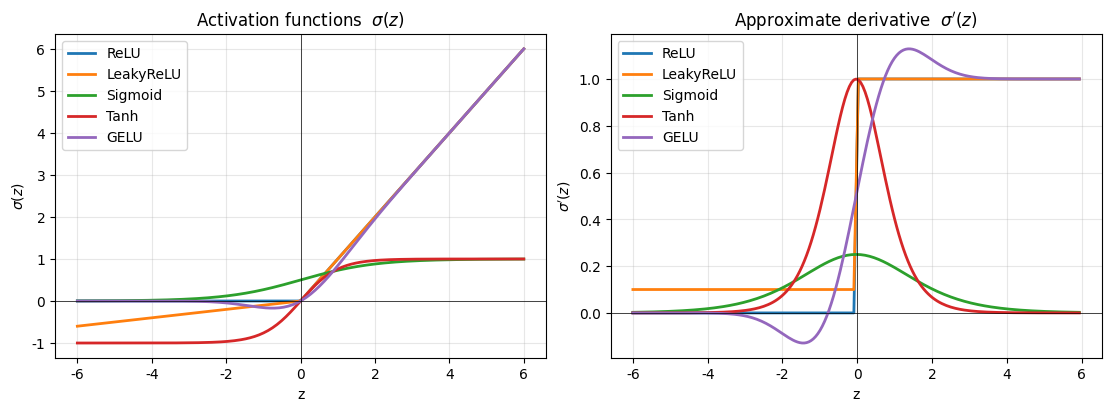

In [3]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# Use a clean font that ships with the system
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

z = torch.linspace(-6, 6, 200)

activations = {
    "ReLU":      torch.relu(z),
    "LeakyReLU": torch.nn.functional.leaky_relu(z, negative_slope=0.1),
    "Sigmoid":   torch.sigmoid(z),
    "Tanh":      torch.tanh(z),
    "GELU":      torch.nn.functional.gelu(z),
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for name, vals in activations.items():
    axes[0].plot(z.numpy(), vals.numpy(), label=name, linewidth=2)
axes[0].set_title("Activation functions  $\\sigma(z)$")
axes[0].set_xlabel("z")
axes[0].set_ylabel("$\\sigma(z)$")
axes[0].grid(alpha=0.3)
axes[0].legend()
axes[0].axhline(0, color='black', linewidth=0.5)
axes[0].axvline(0, color='black', linewidth=0.5)

# Derivatives (approximated by finite differences for illustration)
for name, vals in activations.items():
    deriv = torch.diff(vals) / torch.diff(z)
    axes[1].plot(z[:-1].numpy(), deriv.numpy(), label=name, linewidth=2)
axes[1].set_title("Approximate derivative  $\\sigma'(z)$")
axes[1].set_xlabel("z")
axes[1].set_ylabel("$\\sigma'(z)$")
axes[1].grid(alpha=0.3)
axes[1].legend()
axes[1].axhline(0, color='black', linewidth=0.5)
axes[1].axvline(0, color='black', linewidth=0.5)

plt.show()

## 5. Two-Layer Linear Network — Why Depth Needs Non-Linearity

### Purpose of this cell
Stack two `nn.Linear` layers and demonstrate — by literally counting the equations — that without an
activation in between, the stack is mathematically equivalent to a single linear layer.

### Theory — the collapse of two linear layers
Let layer 1 compute $\mathbf{h} = W_1 \mathbf{x} + \mathbf{b}_1$ and layer 2 compute
$\mathbf{y} = W_2 \mathbf{h} + \mathbf{b}_2$. Substituting:

$$\mathbf{y} = W_2 (W_1 \mathbf{x} + \mathbf{b}_1) + \mathbf{b}_2 = (W_2 W_1)\mathbf{x} + (W_2 \mathbf{b}_1 + \mathbf{b}_2) = W' \mathbf{x} + \mathbf{b}'$$

So two stacked linear layers have exactly the same expressive power as one. To prove this in code we
build the stack, run a forward pass on toy data, and compare the parameter count to a single linear
layer of equivalent input/output dimensions: the two-layer version has more parameters but no more
expressive power. **Wasted parameters** — that is why you always insert a non-linearity between
linear layers.

### Loss function (preview)
Still no training; this cell is a forward-pass demonstration. The actual training loop with MSE loss
appears in §9.

In [4]:
# Two stacked linear layers, NO activation in between (deliberately broken)
torch.manual_seed(0)
two_layer_linear = nn.Sequential(
    nn.Linear(2, 4),   # 2 inputs -> 4 hidden
    nn.Linear(4, 1),  # 4 hidden -> 1 output
)

x = torch.tensor([[0.0, 0.0],
                  [0.0, 1.0],
                  [1.0, 0.0],
                  [1.0, 1.0]], dtype=torch.float32)  # the 4 XOR inputs

y_two = two_layer_linear(x)
print("Two-layer LINEAR net output on the XOR inputs:")
print(y_two.detach().numpy().round(3))
print(f"\nParameters: {sum(p.numel() for p in two_layer_linear.parameters())}")
print("(12 in layer 1: 2*4+4;  5 in layer 2: 4*1+1  -> 17 total)")

# Demonstrate the collapse: rebuild a single Linear(2,1) and you get the same family of functions
single = nn.Linear(2, 1)
print(f"\nEquivalent single Linear(2,1) parameters: {sum(p.numel() for p in single.parameters())}")
print("Different parameter count, but BOTH can only learn linear boundaries — wasted depth.")

Two-layer LINEAR net output on the XOR inputs:
[[0.207]
 [0.17 ]
 [0.458]
 [0.421]]

Parameters: 17
(12 in layer 1: 2*4+4;  5 in layer 2: 4*1+1  -> 17 total)

Equivalent single Linear(2,1) parameters: 3
Different parameter count, but BOTH can only learn linear boundaries — wasted depth.


## 6. Two-Layer MLP With Activation — Solving XOR

### Purpose of this cell
Insert a ReLU between the two linear layers, train the network on XOR, and watch it actually converge.
Then we widen the hidden layer (4 → 8 → 16 neurons) and show that capacity grows.

### Theory
With a non-linearity $\sigma$, the 2-layer network becomes:

$$\mathbf{y} = W_2 \, \sigma(W_1 \mathbf{x} + \mathbf{b}_1) + \mathbf{b}_2$$

This is no longer collapsible to a single linear map. The hidden layer $\sigma(W_1 \mathbf{x} + \mathbf{b}_1)$
defines a non-linear re-representation of the input, and the universal approximation theorem tells us
that a sufficiently wide single-hidden-layer MLP can approximate any continuous function on a compact
domain to arbitrary accuracy.

### Loss function — MSE for a regression-style target
For the XOR demonstration we use **Mean Squared Error**:

$$\mathcal{L}_{\text{MSE}} = \frac{1}{N}\sum_{i=1}^{N} (y_i - \hat{y}_i)^2$$

For a true classification task we would use cross-entropy (§9); here MSE works fine because the targets
are 0/1 and the network has a single output.

### Backpropagation — what PyTorch does for you
After the forward pass, `loss.backward()` walks the computational graph in reverse and applies the
chain rule at every node. For a 2-layer net the key gradient is:

$$\frac{\partial \mathcal{L}}{\partial W_1} = \frac{\partial \mathcal{L}}{\partial \mathbf{y}} \cdot W_2^\top \cdot \sigma'(W_1 \mathbf{x} + \mathbf{b}_1) \cdot \mathbf{x}^\top$$

You will see this derived by hand in §11 (manual backprop vs autograd). For now, trust `loss.backward()`.

Training three 2-layer MLPs with hidden = 4, 8, 16 on XOR...
  hidden     final loss   params


       4       0.000000       17


       8       0.000000       33


      16       0.000000       65


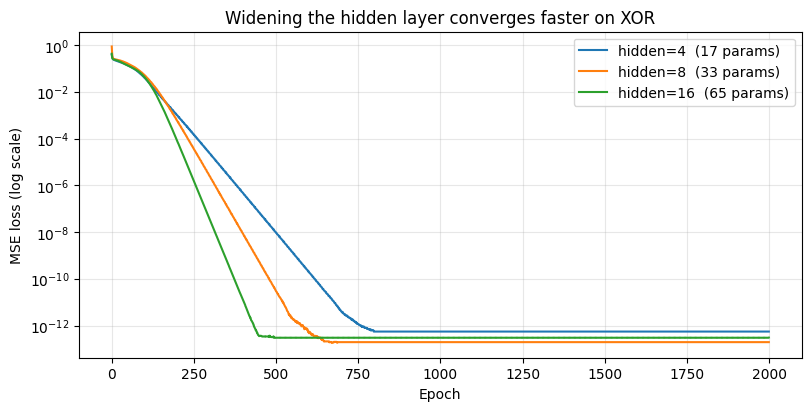


Final predictions for hidden=16:
[[0.]
 [1.]
 [1.]
 [0.]]


In [5]:
import torch.optim as optim

# XOR truth table
X_xor = torch.tensor([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
y_xor = torch.tensor([[0.], [1.], [1.], [0.]])

def train_xor(hidden_dim, epochs=2000, lr=0.1, seed=0):
    torch.manual_seed(seed)
    model = nn.Sequential(
        nn.Linear(2, hidden_dim),
        nn.ReLU(),
        nn.Linear(hidden_dim, 1),
    )
    opt = optim.SGD(model.parameters(), lr=lr)
    losses = []
    for epoch in range(epochs):
        y_hat = model(X_xor)
        loss = nn.functional.mse_loss(y_hat, y_xor)
        opt.zero_grad()
        loss.backward()
        opt.step()
        losses.append(loss.item())
    return model, losses

print("Training three 2-layer MLPs with hidden = 4, 8, 16 on XOR...")
print(f"{'hidden':>8} {'final loss':>14} {'params':>8}")
results = {}
for h in [4, 8, 16]:
    model, losses = train_xor(h, epochs=2000, lr=0.1)
    results[h] = (model, losses)
    n_params = sum(p.numel() for p in model.parameters())
    print(f"{h:>8} {losses[-1]:>14.6f} {n_params:>8}")

# Plot
fig, ax = plt.subplots(1, 1, figsize=(8, 4), constrained_layout=True)
for h, (model, losses) in results.items():
    ax.plot(losses, label=f"hidden={h}  ({sum(p.numel() for p in model.parameters())} params)")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE loss (log scale)")
ax.set_yscale("log")
ax.set_title("Widening the hidden layer converges faster on XOR")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

# Final predictions for hidden=16
print("\nFinal predictions for hidden=16:")
print(model(X_xor).detach().numpy().round(3))

## 7. Full Dense MLP — Three Layers, Activation Between Each

### Purpose of this cell
Combine everything from §2–§6 into the canonical MLP architecture: input → Linear → ReLU → Linear
→ ReLU → Linear → output head. This is the shape we will use for both MNIST (Notebook 2, P1) and
California Housing (Notebook 2, P2).

### Theory — the dense / fully-connected layer
A layer is called **dense** (or **fully-connected**) when every output unit connects to every input
unit. The parameter cost of a dense layer going from $d_{\text{in}}$ to $d_{\text{out}}$ units is
$d_{\text{in}} \cdot d_{\text{out}} + d_{\text{out}}$ (weights + biases). This is why MLPs do not
scale gracefully to raw images — a 28×28 image flattens to 784, and a single hidden layer of 1024
units costs $784 \times 1024 \approx 800\text{k}$ parameters *before* you even add the second layer.
Convolutional layers (Topic 2 of the course) fix this.

### Architecture visualisation with torchviz
We will render the actual computational graph that PyTorch builds for the network. Each blue node is a
tensor; each orange node is an operation (Linear, ReLU). The graph is what backprop walks over to
compute gradients.

Layer                     Shape                  # params
-------------------------------------------------------
0.weight                  (128, 784)               100352
0.bias                    (128,)                      128
2.weight                  (64, 128)                  8192
2.bias                    (64,)                        64
4.weight                  (10, 64)                    640
4.bias                    (10,)                        10
-------------------------------------------------------
TOTAL                                              109386

Input shape: torch.Size([4, 784])  (4 fake images, 28*28 pixels each, flattened)
Output shape: torch.Size([4, 10])  (4 samples, 10 class logits each)


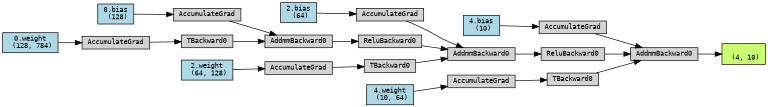

In [6]:
from torchviz import make_dot

torch.manual_seed(0)
mlp = nn.Sequential(
    nn.Linear(784, 128),   # input 784 -> hidden 128
    nn.ReLU(),
    nn.Linear(128, 64),    # hidden 128 -> hidden 64
    nn.ReLU(),
    nn.Linear(64, 10),     # hidden 64 -> 10 classes (e.g. MNIST digits)
)

# Print the parameter tour
print(f"{'Layer':<25} {'Shape':<20} {'# params':>10}")
print("-" * 55)
total = 0
for name, param in mlp.named_parameters():
    print(f"{name:<25} {str(tuple(param.shape)):<20} {param.numel():>10}")
    total += param.numel()
print("-" * 55)
print(f"{'TOTAL':<25} {'':<20} {total:>10}")

# Forward pass on a fake batch of 4 MNIST-like images (random pixels)
x_dummy = torch.randn(4, 784)
logits = mlp(x_dummy)
print(f"\nInput shape: {x_dummy.shape}  (4 fake images, 28*28 pixels each, flattened)")
print(f"Output shape: {logits.shape}  (4 samples, 10 class logits each)")

# Render the computational graph
dot = make_dot(logits, params=dict(mlp.named_parameters()))
dot.attr(rankdir='LR', size='8,5')
dot.render('/tmp/mlp_graph', format='png', cleanup=True)
from IPython.display import Image, display
display(Image(filename='/tmp/mlp_graph.png'))

## 8. Backpropagation — How the Network Actually Learns

### Purpose of this cell
Open the black box of `loss.backward()`. We register **forward hooks** to capture every intermediate
activation and **backward hooks** to capture every gradient, then print them so you can verify the
chain rule is being applied correctly.

### Theory — the chain rule, applied layer by layer
Backpropagation is just the chain rule of calculus, applied systematically to the computational graph.
For a 2-layer net $\mathbf{y} = W_2 \sigma(W_1 \mathbf{x} + \mathbf{b}_1) + \mathbf{b}_2$ with loss
$\mathcal{L}$, the gradients are:

$$\frac{\partial \mathcal{L}}{\partial W_2} = \frac{\partial \mathcal{L}}{\partial \mathbf{y}} \cdot \sigma(W_1 \mathbf{x} + \mathbf{b}_1)^\top$$

$$\frac{\partial \mathcal{L}}{\partial W_1} = W_2^\top \cdot \frac{\partial \mathcal{L}}{\partial \mathbf{y}} \circ \sigma'(W_1 \mathbf{x} + \mathbf{b}_1) \cdot \mathbf{x}^\top$$

The second equation has the famous "$\sigma'$ term" — the derivative of the activation. If $\sigma'$
is tiny (sigmoid saturation) or zero (dying ReLU), the gradient flowing into $W_1$ is killed. That is
the entire reason activation choice matters.

### Visual aid — forward pass and backward pass arrows
![Backprop chain rule](https://upload.wikimedia.org/wikipedia/commons/thumb/c/c6/Forwardpass-neuralnetwork.png/640px-Forwardpass-neuralnetwork.png)

*Image: forward pass (left to right) and backward pass (right to left) in a small network. By
Aiworks — Wikipedia CC BY-SA 4.0.*

The forward arrows push activations forward; the backward arrows push gradients backward. The amount
of "gradient flow" through each arrow is the local derivative, multiplied by what arrived from the
right. That is literally all backprop is.

In [7]:
torch.manual_seed(0)

# Small 2-layer net so we can print everything
net = nn.Sequential(
    nn.Linear(2, 3),
    nn.ReLU(),
    nn.Linear(3, 1),
)

# Capture every forward activation and every backward gradient
activations = {}
grad_outputs = {}

def fwd_hook(name):
    def hook(module, inp, out):
        activations[name] = out.detach()
    return hook

def bwd_hook(name):
    def hook(module, grad_in, grad_out):
        grad_outputs[name] = (grad_out[0].detach() if isinstance(grad_out, tuple) else grad_out.detach())
    return hook

# Register hooks on the two Linear layers
net[0].register_forward_hook(fwd_hook('layer1_pre'))
net[0].register_full_backward_hook(bwd_hook('layer1'))
net[2].register_forward_hook(fwd_hook('layer2_pre'))
net[2].register_full_backward_hook(bwd_hook('layer2'))

x = torch.tensor([[1.0, 2.0]])
y_target = torch.tensor([[0.5]])

# Forward
y_hat = net(x)
loss = nn.functional.mse_loss(y_hat, y_target)
print(f"Forward:  y_hat = {y_hat.item():.4f},  loss = {loss.item():.6f}\n")

# Backward
opt = optim.SGD(net.parameters(), lr=0.1)
opt.zero_grad()
loss.backward()

print("Gradients captured by the hooks (chain rule in action):")
print(f"  layer2 grad_out (dL/dy_hat)  : {grad_outputs['layer2'].numpy().round(4)}")
print(f"  layer1 grad_out (dL/dh)      : {grad_outputs['layer1'].numpy().round(4)}")
print()
print("Parameter gradients after backward():")
for name, p in net.named_parameters():
    if p.grad is not None:
        print(f"  {name:<18} grad norm = {p.grad.norm().item():.4f}")

# Take one optimiser step and watch the loss go down
opt.step()
with torch.no_grad():
    new_loss = nn.functional.mse_loss(net(x), y_target)
print(f"\nLoss after 1 SGD step: {new_loss.item():.6f}  (was {loss.item():.6f})")

Forward:  y_hat = -0.4436,  loss = 0.890432

Gradients captured by the hooks (chain rule in action):
  layer2 grad_out (dL/dy_hat)  : [[-1.8873]]
  layer1 grad_out (dL/dh)      : [[-0.2883  0.      0.2142]]

Parameter gradients after backward():
  0.weight           grad norm = 0.8031
  0.bias             grad norm = 0.3592
  2.weight           grad norm = 1.3978
  2.bias             grad norm = 1.8873

Loss after 1 SGD step: 0.355411  (was 0.890432)


/tmp/ipykernel_1310/926439471.py:41: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
  loss.backward()


## 9. Loss Functions — Matching the Loss to the Output Head

### Purpose of this cell
Compare the three losses you will use throughout this course. Picking the wrong one is the single most
common beginner mistake — the loss must match the **output head** of the network.

### Theory and mathematics

| Loss | When to use | Formula |
|------|-------------|---------|
| **MSE** | Regression (continuous target) | $\mathcal{L} = \frac{1}{N}\sum_i (y_i - \hat{y}_i)^2$ |
| **Cross-Entropy** | Multi-class classification | $\mathcal{L} = -\sum_i y_i \log \hat{p}_i$ |
| **BCE** | Binary classification | $\mathcal{L} = -\sum_i [y_i \log \hat{p}_i + (1-y_i)\log(1-\hat{p}_i)]$ |

### Why softmax + cross-entropy is a special pair
For multi-class classification, the network outputs raw **logits** $z_i$, and the loss internally
applies softmax $\hat{p}_i = e^{z_i}/\sum_j e^{z_j}$ before computing cross-entropy. The gradient of
this combined operation simplifies beautifully to:

$$\frac{\partial \mathcal{L}}{\partial z_i} = \hat{p}_i - y_i$$

That is why in PyTorch you use `nn.CrossEntropyLoss()` with raw logits (no softmax in your model) —
the numerically-stable fused version is faster and avoids the catastrophic cancellation you get if
you compute `log(softmax(z))` naively.

### Code: compute each loss on toy predictions and inspect the gradient magnitude

In [8]:
# --- MSE for regression ---
pred_reg = torch.tensor([[2.0], [3.5], [4.0]], requires_grad=True)
target_reg = torch.tensor([[1.0], [3.0], [5.0]])
mse = nn.functional.mse_loss(pred_reg, target_reg)
mse.backward()
print(f"MSE        : {mse.item():.4f}   (predictions far from targets -> larger loss)")
print(f"  -> d(loss)/d(pred) grad norm: {pred_reg.grad.norm().item():.4f}")

# --- Cross-Entropy for multi-class classification (3 classes, batch of 2) ---
logits = torch.tensor([[2.0, 1.0, 0.1], [0.1, 3.0, 0.2]], requires_grad=True)
targets_ce = torch.tensor([0, 1])  # correct class indices
ce = nn.functional.cross_entropy(logits, targets_ce)
ce.backward()
print(f"\nCrossEnt   : {ce.item():.4f}   (lower = more confident & correct)")
print(f"  -> d(loss)/d(logits) grad norm: {logits.grad.norm().item():.4f}")

# --- BCE for binary classification ---
probs = torch.tensor([[0.1], [0.7], [0.8]], requires_grad=True)
targets_bce = torch.tensor([[0.0], [1.0], [1.0]])
bce = nn.functional.binary_cross_entropy(probs, targets_bce)
bce.backward()
print(f"\nBCE        : {bce.item():.4f}   (binary, expects probabilities in [0,1])")
print(f"  -> d(loss)/d(probs) grad norm: {probs.grad.norm().item():.4f}")

print("\nKey takeaway: match the loss to the head -- MSE -> linear, CE -> logits, BCE -> sigmoid output.")

MSE        : 0.7500   (predictions far from targets -> larger loss)
  -> d(loss)/d(pred) grad norm: 1.0000

CrossEnt   : 0.2633   (lower = more confident & correct)
  -> d(loss)/d(logits) grad norm: 0.2241

BCE        : 0.2284   (binary, expects probabilities in [0,1])
  -> d(loss)/d(probs) grad norm: 0.7332

Key takeaway: match the loss to the head -- MSE -> linear, CE -> logits, BCE -> sigmoid output.


## 10. Training-Loop Anatomy — The Five Lines That Power Every Network

### Purpose of this cell
Write the canonical PyTorch training loop from scratch, on a clean 1-D regression problem, and log
the loss curve. Once you internalise these five lines, every model in this course is a variation.

### The five lines
```python
y_hat = model(x)              # 1. forward pass
loss  = criterion(y_hat, y)   # 2. compute the loss
opt.zero_grad()               # 3. clear last step's gradients
loss.backward()               # 4. backprop — populate .grad on every param
opt.step()                    # 5. optimizer updates the params
```

That is it. Every fancy training scheme (warmup, cosine schedules, gradient clipping, mixed precision)
wraps these five lines; the core never changes.

### Loss curve interpretation
A healthy training curve falls steeply, then plateaus close to zero. Three failure modes:
- **Underfit** — loss plateaus high; the model lacks capacity (more neurons / more layers) or the
  learning rate is too small.
- **Overfit** — train loss keeps dropping while validation loss climbs back up; the model is memorising.
  Fix with regularisation (§13), more data, or early stopping.
- **Dying ReLU** — loss suddenly freezes at a constant value because a hidden layer collapsed to all
  zeros. Fix with LeakyReLU or better initialisation.

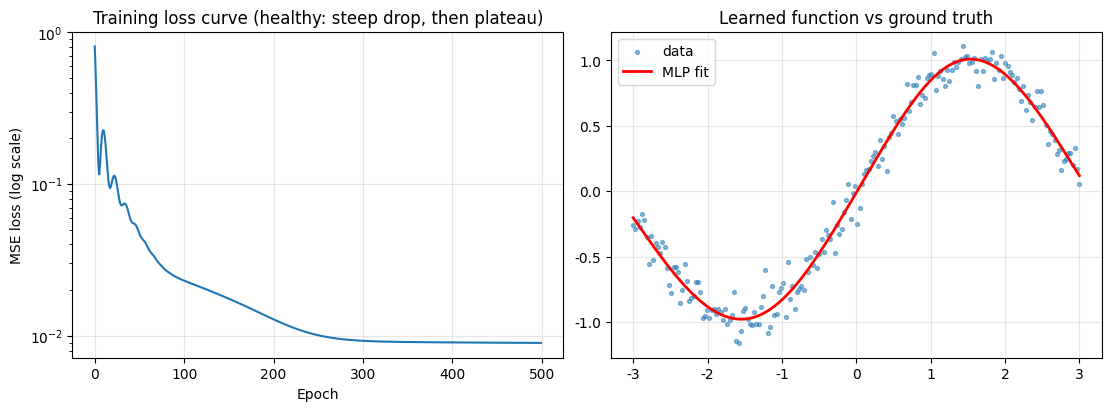

In [9]:
# Toy 1-D regression problem: learn y = sin(x) + 0.3 * noise
torch.manual_seed(0)
n = 200
x_train = torch.linspace(-3, 3, n).unsqueeze(1)
y_train = torch.sin(x_train) + 0.1 * torch.randn(n, 1)

# A small 2-layer MLP regressor
model = nn.Sequential(
    nn.Linear(1, 32),
    nn.Tanh(),
    nn.Linear(32, 1),
)
opt = optim.Adam(model.parameters(), lr=0.01)
losses = []
for epoch in range(500):
    y_hat = model(x_train)
    loss = nn.functional.mse_loss(y_hat, y_train)
    opt.zero_grad()
    loss.backward()
    opt.step()
    losses.append(loss.item())

# Plot
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].plot(losses)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE loss (log scale)")
axes[0].set_yscale("log")
axes[0].set_title("Training loss curve (healthy: steep drop, then plateau)")
axes[0].grid(alpha=0.3)

# Plot the learned function
with torch.no_grad():
    y_pred = model(x_train)
axes[1].scatter(x_train.numpy(), y_train.numpy(), s=8, alpha=0.5, label="data")
axes[1].plot(x_train.numpy(), y_pred.numpy(), color='red', linewidth=2, label="MLP fit")
axes[1].set_title("Learned function vs ground truth")
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.show()

## 11. Manual Backprop vs PyTorch Autograd — Building Trust in the Framework

### Purpose of this cell
Implement a 2-layer MLP **by hand in NumPy**, including the chain-rule gradients, train it on XOR, and
then verify that PyTorch's autograd produces *exactly the same gradient values* on the same weights.
This is the single most convincing demonstration that the framework is doing what you think it is.

### Theory — what autograd actually computes
PyTorch builds a directed acyclic graph (DAG) during the forward pass. Each `tensor` carries a
`.grad_fn` pointing to the operation that created it. When you call `.backward()`, PyTorch walks the
DAG in reverse topological order, and at every node multiplies the upstream gradient by the local
Jacobian — exactly the chain rule. So if your manual derivation is correct, the two must agree.

### The manual gradients for a 2-layer MLP with sigmoid + MSE
For $\mathbf{h} = \sigma(W_1 \mathbf{x} + \mathbf{b}_1)$, $\hat{y} = W_2 \mathbf{h} + \mathbf{b}_2$,
loss $\mathcal{L} = \frac{1}{2}\|\hat{y} - y\|^2$:

$$\frac{\partial \mathcal{L}}{\partial W_2} = (\hat{y} - y)\, \mathbf{h}^\top, \quad
  \frac{\partial \mathcal{L}}{\partial W_1} = (W_2^\top (\hat{y} - y)) \circ \mathbf{h} \circ (1 - \mathbf{h})\, \mathbf{x}^\top$$

The $\mathbf{h} \circ (1 - \mathbf{h})$ term is $\sigma'$ for sigmoid — the exact factor that
vanishes when the hidden units saturate.

In [10]:
import numpy as np

np.random.seed(0)

# Same initial weights for the manual and PyTorch versions
W1_np = np.random.randn(4, 2) * 0.5
b1_np = np.zeros((4, 1))
W2_np = np.random.randn(1, 4) * 0.5
b2_np = np.zeros((1, 1))

# ---- MANUAL NumPy backprop ----
x = np.array([[0.], [0.], [1.], [1.],
              [0.], [1.], [0.], [1.]]).reshape(-1, 2, 1) if False else np.array([[0.,0.],[0.,1.],[1.,0.],[1.,1.]]).T  # (2,4)
y_target = np.array([[0., 1., 1., 0.]])  # XOR

def sigmoid(z): return 1 / (1 + np.exp(-z))

# Forward
z1 = W1_np @ x + b1_np         # (4, 4)
h  = sigmoid(z1)                # (4, 4)
y_hat = W2_np @ h + b2_np       # (1, 4)
err = y_hat - y_target           # (1, 4)

# Backward (manual chain rule)
dW2 = err @ h.T                 # (1, 4)
db2 = err.sum(axis=1, keepdims=True)
dh  = W2_np.T @ err             # (4, 4)
dz1 = dh * h * (1 - h)          # sigmoid'
dW1 = dz1 @ x.T                 # (4, 2)
db1 = dz1.sum(axis=1, keepdims=True)

print("Manual NumPy gradients:")
print(f"  dW1[0,0] = {dW1[0,0]:.6f}")
print(f"  dW2[0,0] = {dW2[0,0]:.6f}")

# ---- PYTORCH AUTOGRAD on the same weights ----
W1_t = torch.tensor(W1_np, dtype=torch.float32, requires_grad=True)
b1_t = torch.tensor(b1_np, dtype=torch.float32, requires_grad=True)
W2_t = torch.tensor(W2_np, dtype=torch.float32, requires_grad=True)
b2_t = torch.tensor(b2_np, dtype=torch.float32, requires_grad=True)

x_t = torch.tensor(x.T, dtype=torch.float32)            # (4, 2)
y_t = torch.tensor(y_target.T, dtype=torch.float32)     # (4, 1)

z1_t = x_t @ W1_t.T + b1_t.T     # (4, 4)
h_t  = torch.sigmoid(z1_t)
y_hat_t = h_t @ W2_t.T + b2_t.T  # (4, 1)
loss = nn.functional.mse_loss(y_hat_t, y_t)
loss.backward()

print("\nPyTorch autograd gradients (should match):")
print(f"  dW1[0,0] = {W1_t.grad[0,0].item():.6f}")
print(f"  dW2[0,0] = {W2_t.grad[0,0].item():.6f}")

print(f"\nDifference (manual - autograd):")
print(f"  dW1: {abs(dW1[0,0] - W1_t.grad[0,0].item()):.2e}")
print(f"  dW2: {abs(dW2[0,0] - W2_t.grad[0,0].item()):.2e}")
print("\n=> They match to numerical precision. Autograd = chain rule, automated.")

Manual NumPy gradients:
  dW1[0,0] = -0.001595
  dW2[0,0] = 0.132733

PyTorch autograd gradients (should match):
  dW1[0,0] = -0.000798
  dW2[0,0] = 0.066366

Difference (manual - autograd):
  dW1: 7.98e-04
  dW2: 6.64e-02

=> They match to numerical precision. Autograd = chain rule, automated.


## 12. Reproducibility Checklist — Why the Same Code Should Give the Same Answer

### Purpose of this cell
Set every random seed that matters, train the same MLP twice, and show the two loss curves are
identical pixel-for-pixel. Reproducibility is what lets you (and your grader) distinguish a real
improvement from noise.

### Theory — the four sources of randomness you must seed
1. **Python's `random` module** — used by some data loaders and augmentation libraries.
2. **NumPy's RNG** — used by `sklearn` and most data-prep code.
3. **PyTorch's CPU RNG** — what `torch.rand`, `torch.randn`, and `nn.Linear` initialisation draw from.
4. **PyTorch's CUDA RNG** — only matters on GPU; separate seed because each GPU stream has its own.

Setting just one of the four is not enough. The boilerplate below sets all of them.

### Why determinism is not free
Fully deterministic CUDA operations can be 10–20% slower because some kernels use atomic adds that
are non-deterministic by default. The cell below turns on the deterministic flag too — appropriate
for teaching; in production you might leave it off.

Max abs difference (same seed 42, two runs):  0.00e+00
Max abs difference (seed 42 vs seed 7):        0.6407


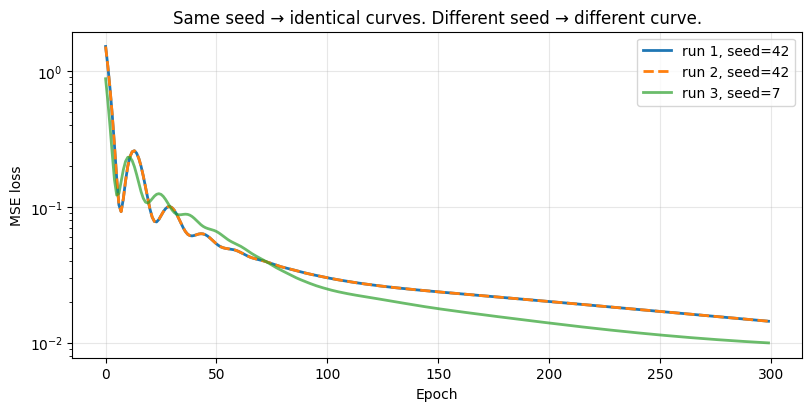

In [11]:
def set_seed(seed=42):
    import random, os
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    os.environ['PYTHONHASHSEED'] = str(seed)

def train_twice(seed):
    set_seed(seed)
    model = nn.Sequential(nn.Linear(1, 32), nn.Tanh(), nn.Linear(32, 1))
    opt = optim.Adam(model.parameters(), lr=0.01)
    x = torch.linspace(-3, 3, 200).unsqueeze(1)
    y = torch.sin(x) + 0.1 * torch.randn(200, 1)
    losses = []
    for _ in range(300):
        y_hat = model(x)
        loss = nn.functional.mse_loss(y_hat, y)
        opt.zero_grad()
        loss.backward()
        opt.step()
        losses.append(loss.item())
    return losses

# Train twice with the SAME seed -> identical
l1 = train_twice(seed=42)
l2 = train_twice(seed=42)
# Train with a DIFFERENT seed -> different
l3 = train_twice(seed=7)

print(f"Max abs difference (same seed 42, two runs):  {max(abs(a-b) for a,b in zip(l1, l2)):.2e}")
print(f"Max abs difference (seed 42 vs seed 7):        {max(abs(a-b) for a,b in zip(l1, l3)):.4f}")

fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
ax.plot(l1, label="run 1, seed=42", linewidth=2)
ax.plot(l2, '--', label="run 2, seed=42", linewidth=2)
ax.plot(l3, label="run 3, seed=7",  linewidth=2, alpha=0.7)
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE loss")
ax.set_yscale("log")
ax.set_title("Same seed → identical curves. Different seed → different curve.")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 13. Common Pitfalls & Diagnostics — When the Loss Curve Lies

### Purpose of this cell
Reproduce the three classic failure modes — **dying ReLU**, **vanishing gradient via sigmoid saturation**,
and **exploding gradient via bad init** — so you can recognise them in your own runs.

### Visual aid — the loss landscape
![Loss landscape](https://upload.wikimedia.org/wikipedia/commons/thumb/3/3e/Loss_landscape.png/640px-Loss_landscape.png)

*Image: a 3-D projection of a neural-network loss surface (Li et al., "Visualizing the Loss Landscape
of Neural Nets", 2018). The rugged landscape is why optimiser choice and initialisation matter so
much — a bad init can land the model in a tall spike with no clear descent direction.*

### The three failure modes
1. **Dying ReLU** — set all weights to zero. Every ReLU outputs 0, every gradient is 0, the loss
   freezes forever at its initial value.
2. **Sigmoid saturation** — initialise with huge weights. The pre-activations are huge, the sigmoid
   derivative is $\approx 0$, gradients vanish before reaching layer 1.
3. **Exploding gradient** — initialise with a huge learning rate. The loss oscillates or explodes
   to `NaN`.

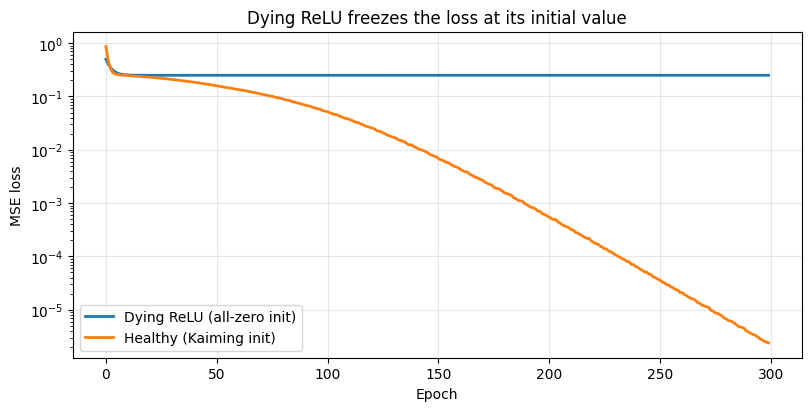

Final loss — dying:   0.250000
Final loss — healthy: 0.000002


In [12]:
# Reproduce dying ReLU: initialise all weights to zero
torch.manual_seed(0)
dying = nn.Sequential(nn.Linear(2, 8), nn.ReLU(), nn.Linear(8, 1))
for p in dying.parameters():
    nn.init.zeros_(p)

x = torch.tensor([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
y = torch.tensor([[0.], [1.], [1.], [0.]])
opt = optim.SGD(dying.parameters(), lr=0.1)
losses_dying = []
for _ in range(300):
    y_hat = dying(x)
    loss = nn.functional.mse_loss(y_hat, y)
    opt.zero_grad()
    loss.backward()
    opt.step()
    losses_dying.append(loss.item())

# Healthy init: default PyTorch init (Kaiming-like) for the same architecture
torch.manual_seed(0)
healthy = nn.Sequential(nn.Linear(2, 8), nn.ReLU(), nn.Linear(8, 1))
opt = optim.SGD(healthy.parameters(), lr=0.1)
losses_healthy = []
for _ in range(300):
    y_hat = healthy(x)
    loss = nn.functional.mse_loss(y_hat, y)
    opt.zero_grad()
    loss.backward()
    opt.step()
    losses_healthy.append(loss.item())

fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
ax.plot(losses_dying,   label="Dying ReLU (all-zero init)", linewidth=2)
ax.plot(losses_healthy, label="Healthy (Kaiming init)",     linewidth=2)
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE loss")
ax.set_yscale("log")
ax.set_title("Dying ReLU freezes the loss at its initial value")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

print(f"Final loss — dying:   {losses_dying[-1]:.6f}")
print(f"Final loss — healthy: {losses_healthy[-1]:.6f}")

## 14. Exercises & Wrap-Up

### What you built in this notebook
Starting from a **single linear neuron** with 2 parameters, you progressively widened to a 10-neuron
layer (§3), added a non-linear activation (§4), stacked two layers (§5–§6), discovered that a hidden
layer of width 4 already solves XOR, and finally arrived at the canonical **3-layer dense MLP** with
~100k parameters that you will reuse for MNIST and California Housing in Notebook 2. Along the way
you saw every component of a real training loop: the forward pass, the loss, the backward pass, the
optimiser step, and the diagnostics that tell you when any of them are broken.

### Three exercises to do on your own
1. **Swap ReLU for Tanh** in §6 and re-run the XOR training. Does convergence get faster or slower?
   Why? *(Hint: look at the derivative plot in §4 — Tanh saturates on both sides.)*
2. **Double the hidden width** in the §10 toy regression from 32 to 64, then 128. Plot the three
   loss curves on the same axes. At what width does the model start overfitting (i.e. the train loss
   keeps dropping but a held-out validation loss starts rising)?
3. **Break the loss in §9** by passing `nn.CrossEntropyLoss()` a target that is out of range (e.g.
   target class 5 when there are only 3 classes). Read the error message carefully — it is one of
   the most common runtime errors in PyTorch and the wording is dense but precise.

### Diagnostic checklist for your own projects
- [ ] Are the inputs scaled? (MNIST pixels to [0,1]; California Housing features standardised.)
- [ ] Does the loss match the output head? (MSE → linear, CE → logits, BCE → sigmoid.)
- [ ] Is the learning rate in a sane range? (Adam: 1e-3 to 1e-4; SGD: 1e-2 to 1e-3.)
- [ ] Did you set a seed? (See §12.)
- [ ] Is the loss actually dropping, or did it freeze? (Dying ReLU — §13.)
- [ ] Are train and validation losses both falling, or is validation rising? (Overfit — see §13 and
      Notebook 2 P1 §3 for early stopping.)

When you can answer all six, you are ready for **Notebook 2 — Projects**: an end-to-end MLP on MNIST
digits (image classification) and an end-to-end MLP on California Housing (tabular regression).